# 09 · Churn Prediction

Predict which *active* customers will make no purchase in the next 90 days, so retention teams can act early.

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

from src.config import *
from src.ingestion.etl import load_processed
D = load_processed()
tx, customers, products, inventory = D["transactions"], D["customers"], D["products"], D["inventory"]
daily = D["daily"]
print(f"Loaded {len(tx):,} clean transaction lines | {tx.customer_id.nunique():,} customers | "
      f"{tx.order_date.min().date()} -> {tx.order_date.max().date()}")

Loaded 54,339 clean transaction lines | 1,455 customers | 2024-01-01 -> 2025-12-31


## 1. Training set

In [2]:
from src.churn.model import make_training_set, train_churn_model, score_customers
X, y, cutoff = make_training_set(tx, customers)
print(f"cutoff {cutoff.date()} | n={len(X)} | churn rate {y.mean():.1%}")

cutoff 2025-10-03 | n=1118 | churn rate 25.9%


## 2. Train & evaluate

In [3]:
bundle = train_churn_model(tx, customers)
pd.Series(bundle["metrics"]).round(3)

roc_auc            0.899
avg_precision      0.819
precision          0.810
recall             0.644
f1                 0.718
base_rate          0.261
n_test           280.000
dtype: float64

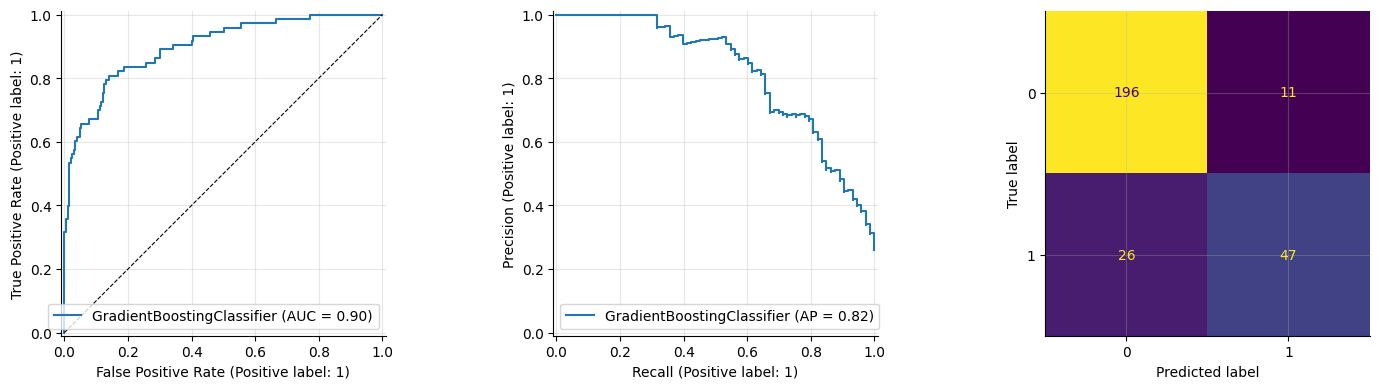

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
_, Xte, _, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
model = bundle["model"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_estimator(model, Xte, yte, ax=ax[0]); ax[0].plot([0,1],[0,1],"k--",lw=.8)
PrecisionRecallDisplay.from_estimator(model, Xte, yte, ax=ax[1])
ConfusionMatrixDisplay.from_estimator(model, Xte, yte, ax=ax[2], colorbar=False)
plt.tight_layout(); plt.show()

## 3. What drives churn?

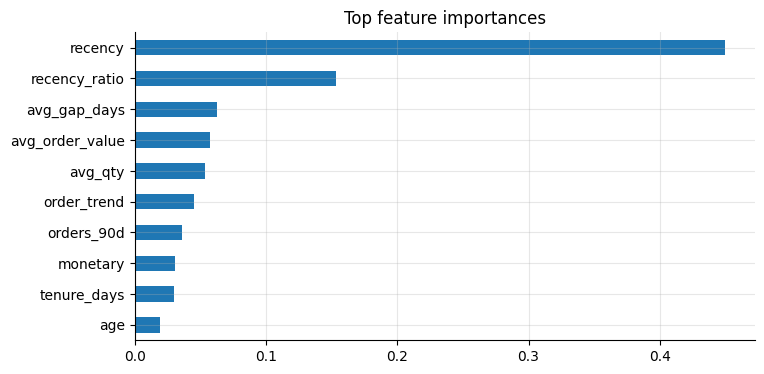

In [5]:
bundle["importance"].head(10).iloc[::-1].plot.barh(title="Top feature importances", figsize=(8, 4)); plt.show()

## 4. Choosing an operating threshold from business costs
A retention offer costs money; a lost customer costs more. Adjust the assumptions below.

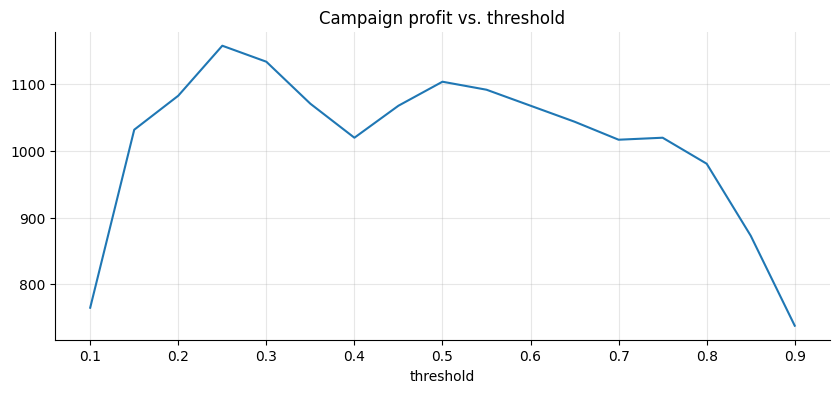

best threshold: 0.25 -> net profit $ 1158


In [6]:
proba = model.predict_proba(Xte)[:, 1]
COST_OFFER, VALUE_SAVED, SAVE_RATE = 15, 120, 0.35   # $ per contact, $ value of a retained customer, P(offer works)
rows = []
for th in np.arange(0.1, 0.91, 0.05):
    contact = proba >= th
    tp = (contact & (yte.values == 1)).sum()
    profit = tp * SAVE_RATE * VALUE_SAVED - contact.sum() * COST_OFFER
    rows.append((round(th, 2), int(contact.sum()), int(tp), profit))
t = pd.DataFrame(rows, columns=["threshold", "contacted", "true churners reached", "net profit $"])
best = t.loc[t["net profit $"].idxmax()]
t.set_index("threshold")["net profit $"].plot(title="Campaign profit vs. threshold"); plt.show()
print("best threshold:", best.threshold, "-> net profit $", round(best["net profit $"]))

## 5. Score all customers as of today

In [7]:
scores = score_customers(bundle, tx, customers)
active = scores[scores.active]
print(active.risk_band.value_counts().to_dict())
active.head(10)

{'Low': 764, 'High': 199, 'Medium': 73}


,customer_id,churn_probability,recency,frequency,monetary,active,risk_band
0,C00310,0.9949,92,33,2998.54,True,High
1,C00191,0.9936,114,40,5915.15,True,High
2,C00187,0.9931,107,61,6938.88,True,High
3,C01054,0.9928,142,121,14151.91,True,High
4,C01362,0.9914,124,90,13348.45,True,High
5,C01225,0.9912,128,89,12820.53,True,High
6,C00516,0.9899,69,66,6692.26,True,High
7,C01050,0.9899,90,72,10630.77,True,High
8,C00389,0.9897,140,38,4103.32,True,High
9,C01271,0.9892,131,59,7929.90,True,High
